# Optimal Active Concurrency Across GPU Models (`B_cap` U-Curves)

Sweeps the **same policy (`CappedPagedOracleSim`)** across `B_cap ∈ {6, 8, 10, 12, 14, 16, Uncapped}` for **4 realistic datacenter GPU configurations** (scaling `a_resident` inversely with `BW_HBM / 3.35 TB/s` from our calibrated H100 SXM profile on **Exgentic SWE-bench, `λ=0.15`, `n=40`**):

1. **H100 PCIe 80GB** (`2.0 TB/s`, `45 GB` KV budget)
2. **H100 SXM 80GB** (`3.35 TB/s`, `48 GB` KV budget — calibrated baseline)
3. **H100 NVL 94GB** (`3.9 TB/s`, `64 GB` KV budget)
4. **H200 SXM 141GB** (`4.8 TB/s`, `96 GB` KV budget)

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time, rate = 40, 42, 8000.0, 0.15

gpus = [
    ("H100 PCIe (2.0 TB/s, 45G KV)", 45.0, 3.35 / 2.0, "#ef4444", "s"),
    ("H100 SXM (3.35 TB/s, 48G KV)", 48.0, 1.0,        "#2563eb", "o"),
    ("H100 NVL (3.9 TB/s, 64G KV)",  64.0, 3.35 / 3.9, "#f59e0b", "D"),
    ("H200 SXM (4.8 TB/s, 96G KV)",  96.0, 3.35 / 4.8, "#10b981", "^"),
]

b_caps = [6, 8, 10, 12, 14, 16, None]

tasks = []
for gname, kv_gb, rscale, _, _ in gpus:
    for b in b_caps:
        lbl = f"{gname}|{b}"
        if b is None:
            tasks.append((lbl, "CappedPagedOracle", kv_gb, rate, n_req, seed, max_time, trace_path, {"resident_scale": rscale}))
        else:
            tasks.append((lbl, "CappedPagedOracle", kv_gb, rate, n_req, seed, max_time, trace_path, {"b_cap": b, "resident_scale": rscale}))

res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, tasks):
        res[k] = s

print(f"{'GPU':30s} | {'B_cap':8s} | {'MeanE2E':9s} | {'LastDone':9s} | {'EvictGB':8s} | {'TTFTp95':8s}")
print("-" * 86)
for gname, _, _, _, _ in gpus:
    for b in b_caps:
        s = res[f"{gname}|{b}"]
        bl = "Uncapped" if b is None else f"{b}"
        print(f"{gname:30s} | {bl:8s} | {s['mean_e2e_s']:7.1f} s | {s['makespan_done_s']:7.1f} s | {s['total_evicted_gb']:6.1f} G | {s['ttft_p95']:6.2f} s")
    print("-" * 86)

GPU                            | B_cap    | MeanE2E   | LastDone  | EvictGB  | TTFTp95 
--------------------------------------------------------------------------------------
H100 PCIe (2.0 TB/s, 45G KV)   | 6        |  2838.9 s |  6020.3 s |  190.0 G |  35.78 s
H100 PCIe (2.0 TB/s, 45G KV)   | 8        |  2759.1 s |  5707.2 s |  732.4 G |  37.64 s
H100 PCIe (2.0 TB/s, 45G KV)   | 10       |  2606.6 s |  5619.6 s | 1611.3 G |  34.26 s
H100 PCIe (2.0 TB/s, 45G KV)   | 12       |  2483.1 s |  5589.3 s | 2380.3 G |  30.09 s
H100 PCIe (2.0 TB/s, 45G KV)   | 14       |  2476.2 s |  5580.8 s | 2695.4 G |  32.29 s
H100 PCIe (2.0 TB/s, 45G KV)   | 16       |  2480.7 s |  5552.0 s | 3043.3 G |  33.67 s
H100 PCIe (2.0 TB/s, 45G KV)   | Uncapped |  2511.8 s |  5538.0 s | 3313.8 G |  39.17 s
--------------------------------------------------------------------------------------
H100 SXM (3.35 TB/s, 48G KV)   | 6        |  2002.9 s |  4253.7 s |  285.9 G |  35.35 s
H100 SXM (3.35 TB/s, 48G KV)   | 8

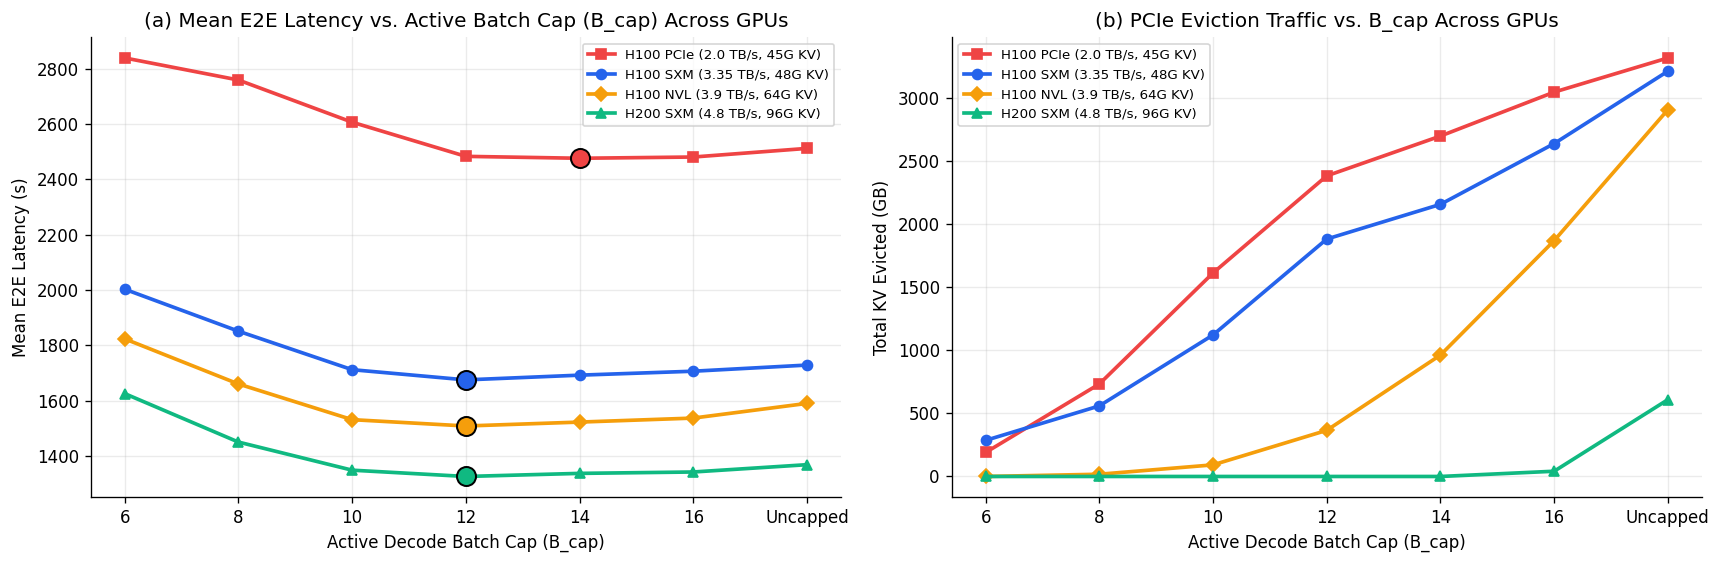

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
xb = np.arange(len(b_caps))
x_lbls = ["6", "8", "10", "12", "14", "16", "Uncapped"]

for gname, _, _, col, mk in gpus:
    e2e = [res[f"{gname}|{b}"]["mean_e2e_s"] for b in b_caps]
    evg = [res[f"{gname}|{b}"]["total_evicted_gb"] for b in b_caps]
    axes[0].plot(xb, e2e, marker=mk, lw=2.2, color=col, label=gname)
    axes[1].plot(xb, evg, marker=mk, lw=2.2, color=col, label=gname)
    best_i = int(np.argmin(e2e))
    axes[0].scatter([best_i], [e2e[best_i]], color=col, s=130, edgecolor="black", lw=1.2, zorder=6)

axes[0].set_title("(a) Mean E2E Latency vs. Active Batch Cap (B_cap) Across GPUs")
axes[0].set_xlabel("Active Decode Batch Cap (B_cap)")
axes[0].set_ylabel("Mean E2E Latency (s)")
axes[0].set_xticks(xb); axes[0].set_xticklabels(x_lbls)
axes[0].legend(fontsize=8.0, loc="upper right")

axes[1].set_title("(b) PCIe Eviction Traffic vs. B_cap Across GPUs")
axes[1].set_xlabel("Active Decode Batch Cap (B_cap)")
axes[1].set_ylabel("Total KV Evicted (GB)")
axes[1].set_xticks(xb); axes[1].set_xticklabels(x_lbls)
axes[1].legend(fontsize=8.0, loc="upper left")

plt.tight_layout()
plt.show()